# Results: zero-shot vs SFT Qwen3-8B

Visualizes the evaluation runs in `outputs/`:
- **Test** (158 questions, 27 patients): zero-shot Qwen3-8B, SFT on clean data (epoch 2)
  and SFT on recovery data (epoch 2, the model chosen on validation).
- **Validation** (145 questions, 22 patients): all four SFT adapters and zero-shot,
  used to choose the SFT model.
- **Training logs** of the two LoRA runs.

*Grounded* means the answer is correct and all required evidence was retrieved and
cited. Each system is one sampled run (temperature 0.7, seed 4880). Confidence
intervals resample **patients** (questions of one patient are correlated), 4,000
draws. Figures are also saved to `docs/figures/`, where the README shows them.

In [1]:
import json
import random
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / 'outputs').exists() else Path.cwd().parent
OUT = ROOT / 'outputs'
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

TEST = {'Zero-shot': 'zero-shot-v6-test.jsonl',
        'SFT clean': 'sft-clean-e2-test.jsonl',
        'SFT recovery': 'sft-recovery-e2-test.jsonl'}
VALIDATION = {'Zero-shot': 'zero-shot-v6-validation.jsonl',
              'SFT clean e1': 'sft-clean-e1-validation.jsonl',
              'SFT clean e2': 'sft-clean-e2-validation.jsonl',
              'SFT recovery e1': 'sft-recovery-e1-validation.jsonl',
              'SFT recovery e2': 'sft-recovery-e2-validation.jsonl'}
TRAINING = {'SFT clean': 'sft-runs/clean-r16-lr1e-4/train-log.jsonl',
            'SFT recovery': 'sft-runs/recovery-r16-lr1e-4/train-log.jsonl'}

# Palette: categorical slots 1-3 (identity of each system, fixed order), status colors
# for episode outcomes (always shown with labels), one-hue blue ramp for magnitude.
COLORS = {'Zero-shot': '#2a78d6', 'SFT clean': '#eb6834', 'SFT recovery': '#1baf7a'}
STATUS = [('completed', 'Submitted an answer', '#0ca30c'),
          ('step_limit', 'Step limit', '#fab219'),
          ('context_limit', 'Context limit', '#ec835a'),
          ('repeated_failure', 'Repeated failure', '#d03b3b')]
BLUES = LinearSegmentedColormap.from_list('blues', ['#f0efec', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
INK, INK_2, INK_3, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e4e3df', '#fcfcfb'
DIFFICULTY = ['simple', 'intermediate', 'complex']

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'legend.frameon': False, 'text.color': INK,
})


def load(name):
    return [r for r in map(json.loads, open(OUT / name)) if r.get('type') == 'example']


def save(fig, name):
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')


test = {k: load(v) for k, v in TEST.items()}
validation = {k: load(v) for k, v in VALIDATION.items()}
for split, runs in (('test', test), ('validation', validation)):
    print(split, {k: len(v) for k, v in runs.items()})

test {'Zero-shot': 158, 'SFT clean': 158, 'SFT recovery': 158}
validation {'Zero-shot': 145, 'SFT clean e1': 145, 'SFT clean e2': 145, 'SFT recovery e1': 145, 'SFT recovery e2': 145}


## Helpers: accuracy and patient-level bootstrap

In [2]:
def grounded(r):
    return float(r['scores']['answer_correct_with_evidence'])


def correct(r):
    return float(r['scores']['answer_correct'])


def bootstrap(runs, metric=grounded, draws=4000, seed=0):
    """Per-system accuracy CIs and a function for paired differences, resampling patients."""
    ids = sorted(r['id'] for r in next(iter(runs.values())))
    value = {name: {r['id']: metric(r) for r in rows} for name, rows in runs.items()}
    patient = {r['id']: r['patient_id'] for r in next(iter(runs.values()))}
    by_patient = defaultdict(list)
    for i in ids:
        by_patient[patient[i]].append(i)
    patients = sorted(by_patient)
    rng = random.Random(seed)
    samples = [[i for p in (rng.choice(patients) for _ in patients) for i in by_patient[p]] for _ in range(draws)]

    def ci(name):
        stats = sorted(np.mean([value[name][i] for i in s]) for s in samples)
        return np.mean([value[name][i] for i in ids]), stats[int(0.025 * draws)], stats[int(0.975 * draws) - 1]

    def paired(a, b):
        stats = sorted(np.mean([value[a][i] - value[b][i] for i in s]) for s in samples)
        point = np.mean([value[a][i] - value[b][i] for i in ids])
        only_a = sum(value[a][i] > value[b][i] for i in ids)
        only_b = sum(value[b][i] > value[a][i] for i in ids)
        return point, stats[int(0.025 * draws)], stats[int(0.975 * draws) - 1], only_a, only_b

    return ci, paired


test_ci, test_paired = bootstrap(test)
val_ci, val_paired = bootstrap(validation)
for name in test:
    m, lo, hi = test_ci(name)
    print(f'{name:14s} test grounded {m:6.1%}  (95% CI {lo:.1%} to {hi:.1%})')

Zero-shot      test grounded   9.5%  (95% CI 5.4% to 14.1%)


SFT clean      test grounded  57.6%  (95% CI 48.4% to 67.9%)
SFT recovery   test grounded  60.1%  (95% CI 52.0% to 68.9%)


## 1. Test accuracy

Headline: grounded accuracy on the 158 test questions, with 95% patient-bootstrap
intervals. Correct-answer accuracy is almost identical for every system, so it is not
plotted separately (see the table at the end).

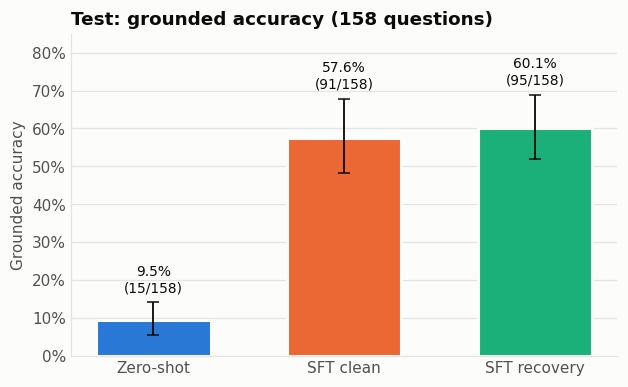

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
names = list(test)
for x, name in enumerate(names):
    m, lo, hi = test_ci(name)
    ax.bar(x, m, width=0.6, color=COLORS[name], edgecolor=SURFACE, linewidth=2)
    ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], color=INK, capsize=4, linewidth=1.2)
    n = int(round(m * len(test[name])))
    ax.text(x, hi + 0.02, f'{m:.1%}\n({n}/{len(test[name])})', ha='center', va='bottom', color=INK, fontsize=9)
ax.set_xticks(range(len(names)), names)
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel('Grounded accuracy')
ax.set_title('Test: grounded accuracy (158 questions)')
ax.grid(axis='x', visible=False)
save(fig, '1-test-accuracy')
plt.show()

## 2. Paired differences on test

Each row compares two systems on the same questions. The dot is the difference in
grounded accuracy; the line is its 95% patient-bootstrap interval. An interval that
crosses zero is not a significant difference.

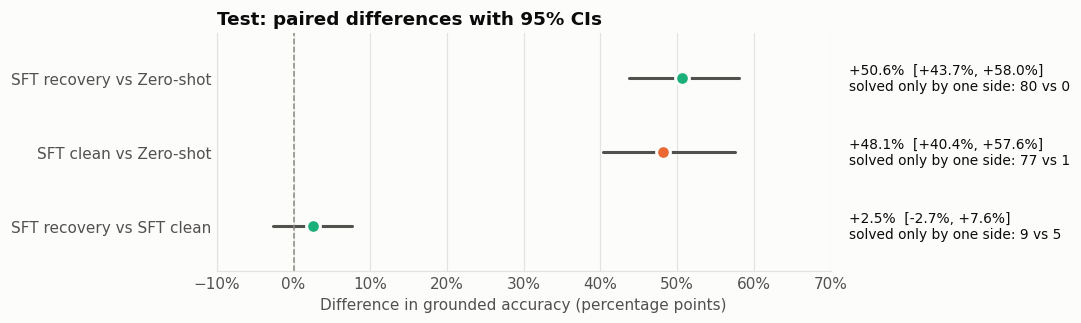

In [4]:
pairs = [('SFT recovery', 'Zero-shot'), ('SFT clean', 'Zero-shot'), ('SFT recovery', 'SFT clean')]
fig, ax = plt.subplots(figsize=(7.2, 2.8))
for y, (a, b) in enumerate(reversed(pairs)):
    d, lo, hi, only_a, only_b = test_paired(a, b)
    ax.plot([lo, hi], [y, y], color=INK_2, linewidth=2, solid_capstyle='round')
    ax.plot(d, y, 'o', color=COLORS[a], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(1.03, y, f'{d:+.1%}  [{lo:+.1%}, {hi:+.1%}]\nsolved only by one side: {only_a} vs {only_b}',
            va='center', color=INK, fontsize=9, transform=ax.get_yaxis_transform())
ax.axvline(0, color=INK_3, linewidth=1, linestyle='--')
ax.set_yticks(range(len(pairs)), [f'{a} vs {b}' for a, b in reversed(pairs)])
ax.set_ylim(-0.6, len(pairs) - 0.4)
ax.set_xlim(-0.1, 0.7)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel('Difference in grounded accuracy (percentage points)')
ax.set_title('Test: paired differences with 95% CIs')
ax.grid(axis='y', visible=False)
save(fig, '2-test-paired-differences')
plt.show()

## 3. Accuracy by difficulty (test)

Difficulty is a provisional label assigned per family. Complex has only 18 questions,
so its bars are noisy.

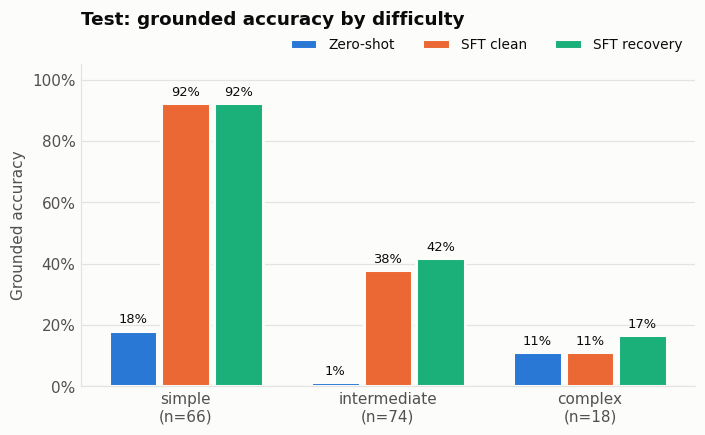

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
width = 0.26
for k, name in enumerate(test):
    for x, level in enumerate(DIFFICULTY):
        rows = [r for r in test[name] if r['complexity'] == level]
        value = np.mean([grounded(r) for r in rows])
        ax.bar(x + (k - 1) * width, value, width=width - 0.02, color=COLORS[name],
               edgecolor=SURFACE, linewidth=2, label=name if x == 0 else None)
        ax.text(x + (k - 1) * width, value + 0.015, f'{value:.0%}', ha='center', va='bottom', fontsize=8.5, color=INK)
counts = {level: sum(r['complexity'] == level for r in test['Zero-shot']) for level in DIFFICULTY}
ax.set_xticks(range(3), [f'{level}\n(n={counts[level]})' for level in DIFFICULTY])
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel('Grounded accuracy')
ax.set_title('Test: grounded accuracy by difficulty', pad=26)
ax.legend(ncols=3, loc='lower right', bbox_to_anchor=(1, 1.0), fontsize=9)
ax.grid(axis='x', visible=False)
save(fig, '3-test-by-difficulty')
plt.show()

## 4. Accuracy by family (test)

Cell color is grounded accuracy; the text gives solved / questions. Families are
sorted by the number of test questions.

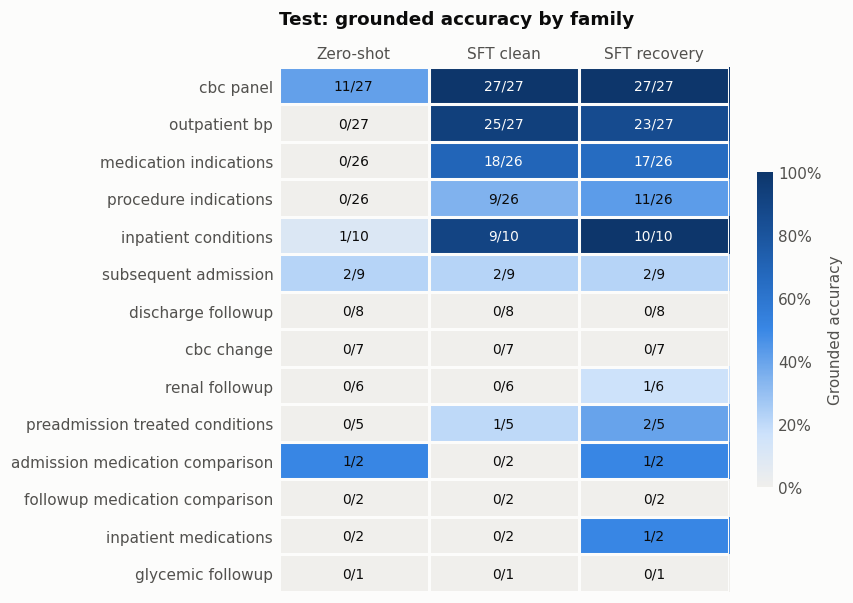

In [6]:
families = sorted({r['family'] for r in test['Zero-shot']},
                  key=lambda f: (-sum(r['family'] == f for r in test['Zero-shot']), f))
names = list(test)
grid = np.zeros((len(families), len(names)))
labels = [[''] * len(names) for _ in families]
for i, family in enumerate(families):
    for j, name in enumerate(names):
        rows = [r for r in test[name] if r['family'] == family]
        solved = int(sum(grounded(r) for r in rows))
        grid[i, j] = solved / len(rows)
        labels[i][j] = f'{solved}/{len(rows)}'

fig, ax = plt.subplots(figsize=(6.6, 6.2))
image = ax.imshow(grid, cmap=BLUES, vmin=0, vmax=1, aspect='auto')
for i in range(len(families)):
    for j in range(len(names)):
        ax.text(j, i, labels[i][j], ha='center', va='center', fontsize=9,
                color=SURFACE if grid[i, j] > 0.55 else INK)
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(families)), [f.replace('_', ' ') for f in families])
ax.tick_params(axis='x', labeltop=True, labelbottom=False)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(names)), minor=True)
ax.set_yticks(np.arange(-0.5, len(families)), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=2)
ax.tick_params(which='minor', length=0)
bar = fig.colorbar(image, ax=ax, shrink=0.6, format=plt.matplotlib.ticker.PercentFormatter(1))
bar.outline.set_visible(False)
bar.set_label('Grounded accuracy', color=INK_2)
ax.set_title('Test: grounded accuracy by family', pad=28)
save(fig, '4-test-by-family')
plt.show()

## 5. Effort (test)

Two measures with different scales, shown side by side rather than on one axis.
Left: tool calls per question by difficulty. Right: model input tokens per question.

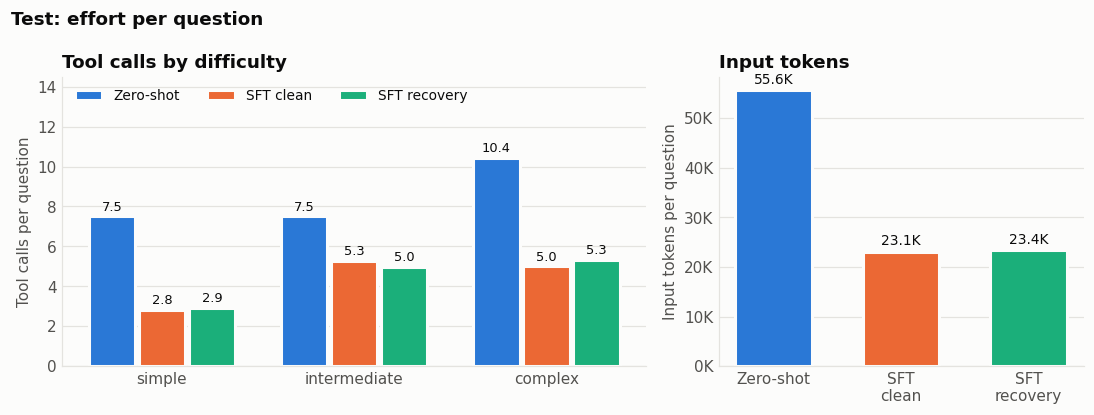

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={'width_ratios': [1.6, 1]})
width = 0.26
for k, name in enumerate(test):
    for x, level in enumerate(DIFFICULTY):
        rows = [r for r in test[name] if r['complexity'] == level]
        value = np.mean([r['metrics']['tool_calls'] for r in rows])
        left.bar(x + (k - 1) * width, value, width=width - 0.02, color=COLORS[name],
                 edgecolor=SURFACE, linewidth=2, label=name if x == 0 else None)
        left.text(x + (k - 1) * width, value + 0.15, f'{value:.1f}', ha='center', va='bottom', fontsize=8.5)
left.set_xticks(range(3), DIFFICULTY)
left.set_ylabel('Tool calls per question')
left.set_title('Tool calls by difficulty')
left.legend(ncols=3, loc='upper left', fontsize=9)
left.set_ylim(0, 14.5)
left.grid(axis='x', visible=False)

names = list(test)
for x, name in enumerate(names):
    value = np.mean([r['metrics']['input_tokens'] for r in test[name]])
    right.bar(x, value, width=0.6, color=COLORS[name], edgecolor=SURFACE, linewidth=2)
    right.text(x, value + 800, f'{value / 1000:.1f}K', ha='center', va='bottom', fontsize=9)
right.set_xticks(range(len(names)), [n.replace(' ', '\n') for n in names])
right.set_ylabel('Input tokens per question')
right.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v / 1000:.0f}K'))
right.set_title('Input tokens')
right.grid(axis='x', visible=False)
fig.suptitle('Test: effort per question', x=0.01, ha='left', fontsize=12, fontweight='semibold')
fig.tight_layout()
save(fig, '5-test-effort')
plt.show()

## 6. How episodes ended (test)

Share of the 158 test episodes by outcome. Zero-shot rarely submits an answer; most of
its episodes run out of context or repeat an invalid action until the episode stops.

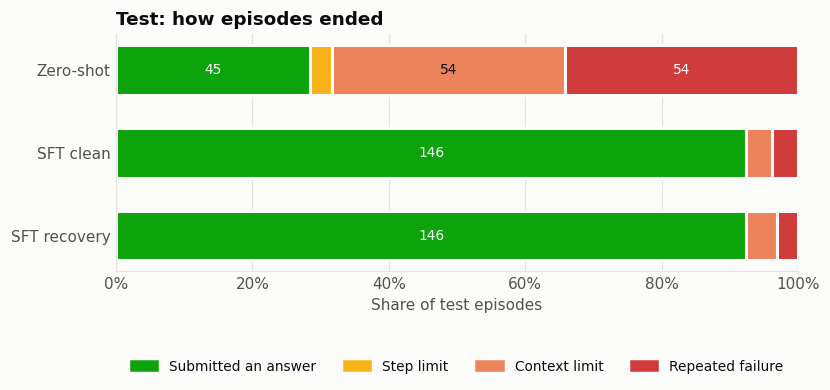

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
names = list(test)
for y, name in enumerate(reversed(names)):
    counts = Counter(r['status'] for r in test[name])
    left_edge = 0
    for status, label, color in STATUS:
        share = counts.get(status, 0) / len(test[name])
        if share == 0:
            continue
        ax.barh(y, share, left=left_edge, height=0.6, color=color, edgecolor=SURFACE, linewidth=2)
        if share >= 0.06:
            ax.text(left_edge + share / 2, y, f'{counts[status]}', ha='center', va='center', fontsize=9,
                    color=INK if status in ('step_limit', 'context_limit') else SURFACE)
        left_edge += share
ax.set_yticks(range(len(names)), list(reversed(names)))
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel('Share of test episodes')
ax.set_title('Test: how episodes ended')
present = {r['status'] for rows in test.values() for r in rows}
handles = [plt.matplotlib.patches.Patch(color=color, label=label) for status, label, color in STATUS if status in present]
ax.legend(handles=handles, ncols=len(handles), loc='upper center', bbox_to_anchor=(0.5, -0.32), fontsize=9)
ax.grid(axis='y', visible=False)
save(fig, '6-test-outcomes')
plt.show()

## 7. Choosing the SFT model on validation

Grounded accuracy of every candidate on the 145 validation questions. Hatched bars are
epoch 1, solid bars epoch 2. The rule was to take the highest validation score:
recovery data, epoch 2.

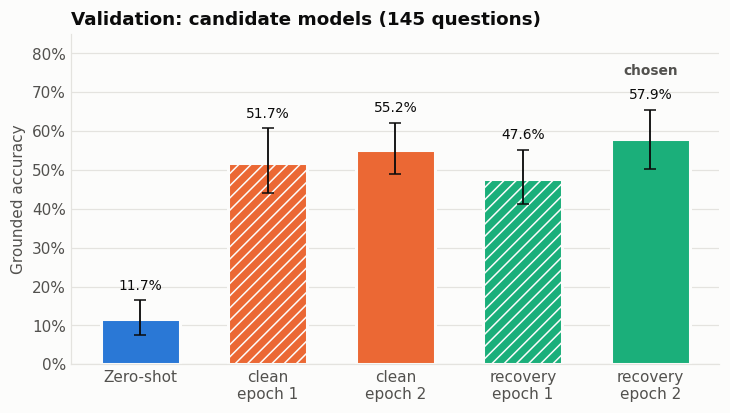

SFT recovery e2 vs SFT recovery e1: +10.3% (95% CI +5.0% to +15.9%)
SFT clean e2 vs SFT clean e1: +3.4% (95% CI -3.1% to +10.2%)
SFT recovery e2 vs SFT clean e2: +2.8% (95% CI -2.2% to +7.6%)


In [9]:
fig, ax = plt.subplots(figsize=(7.6, 3.9))
names = list(validation)
for x, name in enumerate(names):
    family = 'Zero-shot' if name == 'Zero-shot' else ('SFT clean' if 'clean' in name else 'SFT recovery')
    m, lo, hi = val_ci(name)
    ax.bar(x, m, width=0.62, color=COLORS[family], edgecolor=SURFACE, linewidth=2,
           hatch='///' if name.endswith('e1') else None)
    ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], color=INK, capsize=4, linewidth=1.2)
    ax.text(x, hi + 0.02, f'{m:.1%}', ha='center', va='bottom', fontsize=9)
chosen = names.index('SFT recovery e2')
ax.annotate('chosen', xy=(chosen, val_ci('SFT recovery e2')[2] + 0.09), ha='center', fontsize=9,
            color=INK_2, fontweight='semibold')
ax.set_xticks(range(len(names)), [n.replace('SFT ', '').replace(' e', '\nepoch ') for n in names])
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel('Grounded accuracy')
ax.set_title('Validation: candidate models (145 questions)')
ax.grid(axis='x', visible=False)
save(fig, '7-validation-selection')
plt.show()

for a, b in [('SFT recovery e2', 'SFT recovery e1'), ('SFT clean e2', 'SFT clean e1'), ('SFT recovery e2', 'SFT clean e2')]:
    d, lo, hi, only_a, only_b = val_paired(a, b)
    print(f'{a} vs {b}: {d:+.1%} (95% CI {lo:+.1%} to {hi:+.1%})')

## 8. Training curves

Left: training loss per optimizer step (thin line) and its moving average (thick).
Right: dev loss, evaluated every 50 steps and at each epoch end. Both are completion-token
cross-entropy on a log scale. The two variants' dev sets differ slightly, so their dev
losses are not directly comparable.

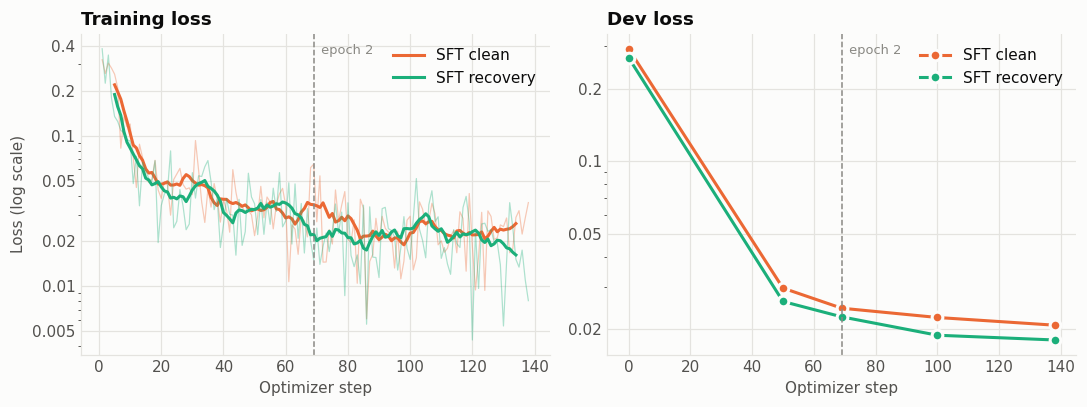

In [10]:
logs = {name: [json.loads(line) for line in open(OUT / path)] for name, path in TRAINING.items()}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
for name, rows in logs.items():
    steps = [r for r in rows if r['event'] == 'step']
    x = np.array([r['step'] for r in steps])
    y = np.array([r['loss'] for r in steps])
    smooth = np.convolve(y, np.ones(9) / 9, mode='valid')
    left.plot(x, y, color=COLORS[name], linewidth=0.8, alpha=0.35)
    left.plot(x[4:-4], smooth, color=COLORS[name], linewidth=2, label=name)
    dev = [(0, r['dev_loss']) if r['event'] == 'start' else (r['step'], r['dev_loss'])
           for r in rows if r.get('dev_loss') is not None and (r['event'] in ('start', 'epoch') or r['step'] % 50 == 0)]
    dev = sorted(set(dev))
    right.plot([d[0] for d in dev], [d[1] for d in dev], '-o', color=COLORS[name], linewidth=2,
               markersize=7, markeredgecolor=SURFACE, markeredgewidth=2, label=name)
for axis in (left, right):
    axis.set_yscale('log')
    axis.yaxis.set_major_locator(plt.matplotlib.ticker.FixedLocator([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]))
    axis.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
    axis.yaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
    axis.set_xlabel('Optimizer step')
    axis.axvline(69, color=INK_3, linewidth=1, linestyle='--')
    axis.text(70, 0.97, ' epoch 2', color=INK_3, fontsize=8.5, va='top', transform=axis.get_xaxis_transform())
    axis.legend()
left.set_ylabel('Loss (log scale)')
left.set_title('Training loss')
right.set_title('Dev loss')
fig.tight_layout()
save(fig, '8-training-curves')
plt.show()

## Summary table

In [11]:
def row(name, rows):
    q = len(rows)
    families = defaultdict(list)
    for r in rows:
        families[r['family']].append(grounded(r))
    return (name, q, np.mean([grounded(r) for r in rows]), np.mean([correct(r) for r in rows]),
            np.mean([np.mean(v) for v in families.values()]), sum(r['status'] == 'completed' for r in rows),
            np.mean([r['metrics']['tool_calls'] for r in rows]), np.mean([r['metrics']['input_tokens'] for r in rows]))


print(f"{'split':10s} {'system':16s} {'n':>4s} {'grounded':>9s} {'correct':>8s} {'macro':>7s} {'submitted':>9s} {'tools/q':>8s} {'in tok/q':>9s}")
for split, runs in (('test', test), ('validation', validation)):
    for name, rows in runs.items():
        n, q, g, c, macro, sub, tools, tokens = row(name, rows)
        print(f'{split:10s} {n:16s} {q:4d} {g:9.1%} {c:8.1%} {macro:7.1%} {sub:9d} {tools:8.1f} {tokens:9,.0f}')

split      system              n  grounded  correct   macro submitted  tools/q  in tok/q
test       Zero-shot         158      9.5%    10.8%    8.8%        45      7.8    55,621
test       SFT clean         158     57.6%    57.6%   30.6%       146      4.2    23,141
test       SFT recovery      158     60.1%    60.1%   40.8%       146      4.2    23,378
validation Zero-shot         145     11.7%    11.7%    7.1%        45      8.7    60,702
validation SFT clean e1      145     51.7%    52.4%   46.9%       130      4.8    23,852
validation SFT clean e2      145     55.2%    55.9%   39.3%       135      4.7    24,139
validation SFT recovery e1   145     47.6%    48.3%   41.7%       135      3.4    17,967
validation SFT recovery e2   145     57.9%    58.6%   48.1%       136      4.4    21,271
